In [1]:
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn as sk
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Flatten, Input, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.initializers import HeNormal
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import SGD, Adam

# --- Comprobación de GPU y limpieza básica de VRAM para TensorFlow ---

# Libera gráficos/modelos previos en esta sesión de Keras/TensorFlow
tf.keras.backend.clear_session()
gc.collect()

gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    print("❌ TensorFlow no detecta GPU. Se usará CPU.")
else:
    print(f"[CORRECTO] ----- GPU(s) detectada(s): {gpus}")

    # Permite crecimiento dinámico de memoria (evita reservar toda la VRAM de golpe)
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(f"[WARNING] ----- No se pudo activar memory_growth (normal si TF ya inició GPU): {e}")

    # Limpia estadísticas de memoria (si está disponible)
    try:
        tf.config.experimental.reset_memory_stats("GPU:0")
    except Exception:
        pass

    # Test rápido de cómputo en GPU
    try:
        with tf.device("/GPU:0"):
            a = tf.random.normal((1024, 1024))
            b = tf.random.normal((1024, 1024))
            _ = tf.matmul(a, b)
        print("[CORRECTO] ----- Prueba de operación en GPU completada.")
    except Exception as e:
        print(f"[ERROR] ----- Error al ejecutar en GPU: {e}")

    # Muestra memoria actual/pico usada por TF en GPU
    try:
        mem = tf.config.experimental.get_memory_info("GPU:0")
        print(f"VRAM TF -> actual: {mem['current'] / 1024**2:.1f} MB | pico: {mem['peak'] / 1024**2:.1f} MB")
    except Exception:
        pass

[CORRECTO] ----- GPU(s) detectada(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
[CORRECTO] ----- Prueba de operación en GPU completada.
VRAM TF -> actual: 12.0 MB | pico: 16.0 MB


In [2]:
## 0. Import data
import kagglehub

path = kagglehub.dataset_download("chukwuemeka64/mortgage-data")
print("Path to dataset files:", str(path))

# Load the dataset as pandas DataFrame
df = pd.read_csv(path + "/mortgage_loan_dataset.csv")
print("Data loaded successfully. Shape:", df.shape, "\n")

df.head(3)

Path to dataset files: /home/samuel/.cache/kagglehub/datasets/chukwuemeka64/mortgage-data/versions/1
Data loaded successfully. Shape: (49990, 14) 



,Gender,Age,Married,Education,Job,Employment Years,Annual Income (USD),Interest Rate,Down Payment (USD),Credit Score,Existing Monthly Debt (USD),Area,Loans Repaid,Max Loan Amount (USD)
0,Male,36,Yes,PhD,Software Engineer,13,134183.86,0.08,101706.78,682,2045.80,Urban,3,498842.67
1,Female,63,No,High School,Freelancer,37,68884.95,0.03,46324.29,823,804.73,Suburban,10,536232.53
2,Female,33,Yes,PhD,Nurse,11,76396.27,0.03,13045.79,813,1050.54,Urban,0,518884.47


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

## 1.   
# Regression problem: Predicting the mortgage loan amount based on various features

y = df['Max Loan Amount (USD)'].copy() # Target variable
X = df.drop(columns=['Max Loan Amount (USD)']).copy() # Features

columns_X = X.columns
print("Features:", columns_X, "\n")
print("Target variable:", y.name, ".\nType:", y.dtype)

print(60 * "-")

data_types_X = X.dtypes
print("Previous to data transformation:")
print("Data types of features:\n", data_types_X)

print("Variables that are not numeric:\n", X.select_dtypes(exclude=np.number).columns)
print("-" * 60)


# Feature engineering
binary_columns = ['Gender', 'Married']
one_hot_columns = ['Education', 'Job', 'Area']

preprocessor = ColumnTransformer(
    transformers=[
        ('binary', OrdinalEncoder(), binary_columns),
        
        ('onehot', OneHotEncoder(drop='first', sparse_output=False), one_hot_columns)
    ],
    remainder='passthrough', # Mantiene intactas las variables numéricas restantes
    verbose_feature_names_out=False
)


one_hot = OneHotEncoder(drop='first', sparse_output=False)
df['Gender'] = one_hot.fit_transform(df[['Gender']]).astype(int)
df['Married'] = one_hot.fit_transform(df[['Married']]).astype(int)

X = pd.DataFrame(
    preprocessor.fit_transform(X),
    columns=preprocessor.get_feature_names_out(),
    index=X.index
)

print("After transformation:")
print("Data types of features:\n", X.dtypes)
print("Variables that are not numeric:\n", X.select_dtypes(exclude=np.number).columns)
print("-" * 60)
print("Transformed shape:", X.shape)
X.head(3)
# encode categorical variables

Features: Index(['Gender', 'Age', 'Married', 'Education', 'Job', 'Employment Years',
       'Annual Income (USD)', 'Interest Rate', 'Down Payment (USD)',
       'Credit Score', 'Existing Monthly Debt (USD)', 'Area', 'Loans Repaid'],
      dtype='str') 

Target variable: Max Loan Amount (USD) .
Type: float64
------------------------------------------------------------
Previous to data transformation:
Data types of features:
 Gender                             str
Age                              int64
Married                            str
Education                          str
Job                                str
Employment Years                 int64
Annual Income (USD)            float64
Interest Rate                  float64
Down Payment (USD)             float64
Credit Score                     int64
Existing Monthly Debt (USD)    float64
Area                               str
Loans Repaid                     int64
dtype: object
Variables that are not numeric:
 Index(['Gender', '

,Gender,Married,Education_High School,Education_Master's,Education_PhD,Job_Banker,Job_Business Owner,Job_Doctor,Job_Engineer,Job_Freelancer,...,Area_Suburban,Area_Urban,Age,Employment Years,Annual Income (USD),Interest Rate,Down Payment (USD),Credit Score,Existing Monthly Debt (USD),Loans Repaid
0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,36.0,13.0,134183.86,0.08,101706.78,682.0,2045.80,3.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,63.0,37.0,68884.95,0.03,46324.29,823.0,804.73,10.0
2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,33.0,11.0,76396.27,0.03,13045.79,813.0,1050.54,0.0



--- Entrenando: Pequeña ---

--- Entrenando: Mediana ---

--- Entrenando: Grande ---


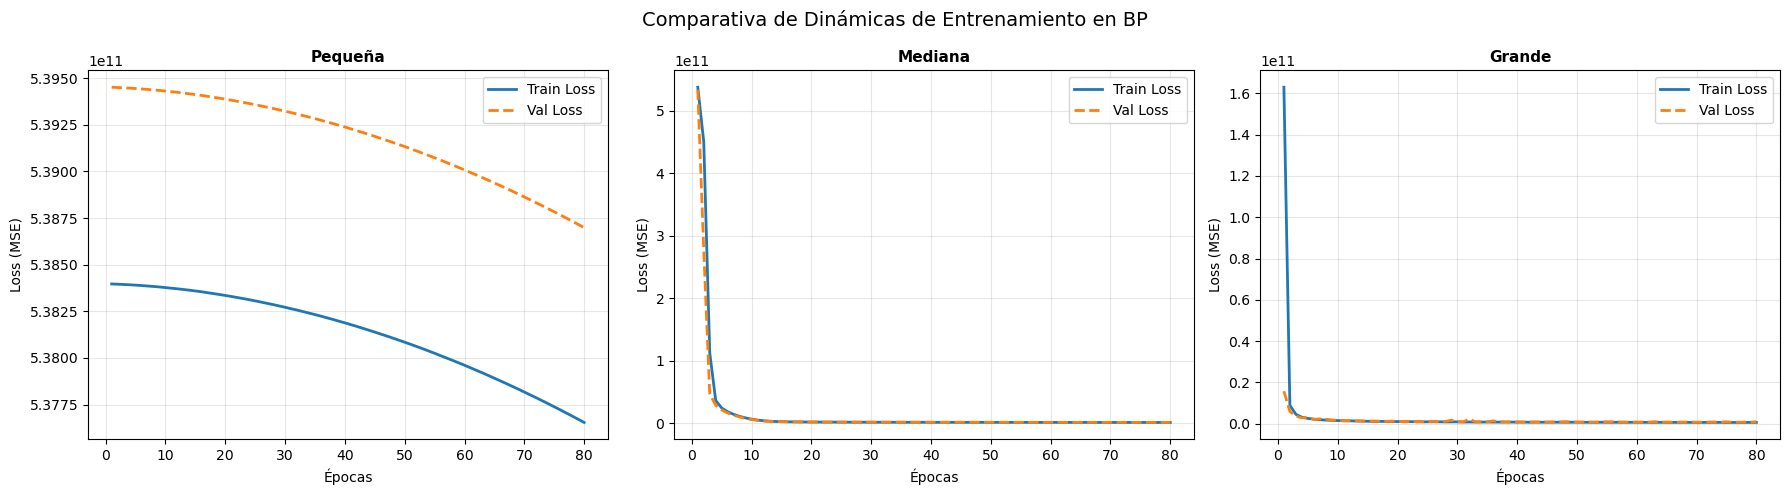

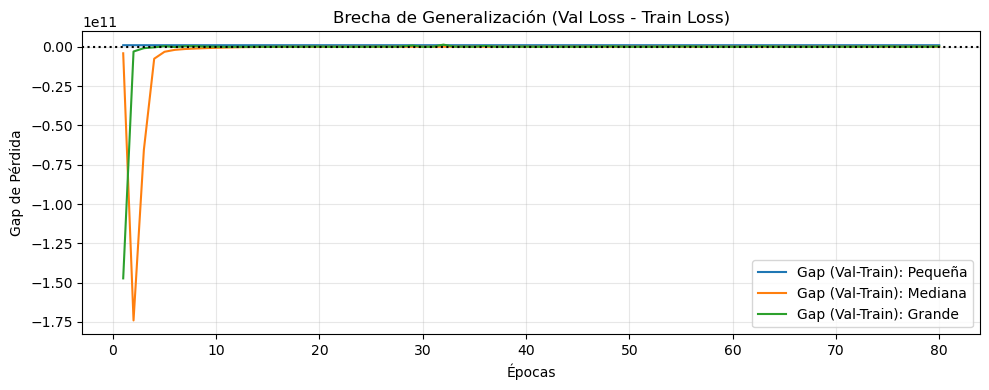

In [10]:
## 2. Definición de la arquitectura de la red neuronal --- IGNORE ---
# Comparamos diferentes arquitecturas con distinta profundidad y monitorizamos el comportamiento de la pérdida (loss) durante el entrenamiento.
# Forzamos un poco la arquitectura para que se vea el efecto de la profundidad y la función de activación en el entrenamiento y la generalización.


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


def build_experiment_model(
    input_dim,
    num_layers=2,
    neurons=64,
    activation="relu",
    optimizer="adam",
    lr=0.01,
):
    """
    Red neuronal densa (fully-connected) con:
    - Varias capas ocultas
    - Mismo número de neuronas por capa

    """

    # input layer:
    inputs = Input(shape=(input_dim,))
    x = inputs 

    # Loop for adding hidden layers
    for _ in range(num_layers):
        x = Dense(
            neurons,
            activation=activation,
            # kernel_initializer="glorot_uniform"
            # if activation == "sigmoid"
            # else "he_normal",
        )(x)

    # output layer:
    outputs = Dense(1, activation="linear")(x)

    model = Model(inputs=inputs, outputs=outputs)


    # Compilation:
    if optimizer == "sgd":
        opt = SGD(learning_rate=lr)
    else:
        opt = Adam(learning_rate=lr)
    model.compile(
        optimizer=opt, loss="mean_squared_error", metrics=["mae"]
    )  # MSE acentúa el gradiente
    return model


configs = {
    "Pequeña": {
        "num_layers": 1,
        "neurons": 8,
        "activation": "relu",
        "optimizer": "adam",
        "lr": 0.0001,
    },

    "Mediana": {
        "num_layers": 5,
        "neurons": 64,
        "activation": "relu",
        "optimizer": "adam",
        "lr": 0.0001,
    },

    "Grande": {
        "num_layers": 70,
        "neurons": 64,
        "activation": "relu",
        "optimizer": "adam",
        "lr": 0.0001,
    },
}

histories = {}
epochs = 80

for name, cfg in configs.items():
    print(f"\n--- Entrenando: {name} ---")
    model = build_experiment_model(
        input_dim=X_train_scaled.shape[1],
        num_layers=cfg["num_layers"],
        neurons=cfg["neurons"],
        activation=cfg["activation"],
        optimizer=cfg["optimizer"],
        lr=cfg["lr"],
    )

    hist = model.fit(
        X_train_scaled,
        y_train,
        validation_split=0.2,
        epochs=epochs,
        batch_size=64,
        verbose=0,
    )
    histories[name] = hist.history

# --- Gráfica de Pérdida de Entrenamiento vs Validación ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(range(1, epochs + 1), h["loss"], label="Train Loss", linewidth=2)
    ax.plot(
        range(1, epochs + 1),
        h["val_loss"],
        label="Val Loss",
        linestyle="--",
        linewidth=2,
    )
    ax.set_title(name, fontsize=11, fontweight="bold")
    ax.set_xlabel("Épocas")
    ax.set_ylabel("Loss (MSE)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Comparativa de Dinámicas de Entrenamiento en BP", fontsize=14)
plt.tight_layout()
plt.show()

# --- Gráfica de GAP (Generalización y Sobreajuste) ---
plt.figure(figsize=(10, 4))
for name, h in histories.items():
    gap = np.array(h["val_loss"]) - np.array(h["loss"])
    plt.plot(range(1, epochs + 1), gap, label=f"Gap (Val-Train): {name}")

plt.axhline(0, color="black", linestyle=":")
plt.title("Brecha de Generalización (Val Loss - Train Loss)")
plt.xlabel("Épocas")
plt.ylabel("Gap de Pérdida")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,Modelo,Capas ocultas,Neuronas/capa,Activación,Parámetros,Mejor época,Train MSE final,Val MSE final,Train MAE final,Val MAE final,Mejor Val MSE,Mejor Val MAE,Gap MSE final,Gap MAE final
0,Pequeña,1,8,relu,225,80,"537,653,706,752.00","538,698,579,968.00","663,159.25","663,705.06","538,698,579,968.00","663,705.06","1,044,873,216.00",545.81
1,Mediana,5,64,relu,"18,433",80,"1,229,451,648.00","1,307,382,272.00","26,441.91","27,321.15","1,307,382,272.00","27,299.12","77,930,624.00",879.24
2,Grande,70,64,relu,"288,833",79,"601,368,064.00","955,143,808.00","18,614.38","23,806.46","685,923,200.00","19,778.40","353,775,744.00","5,192.08"


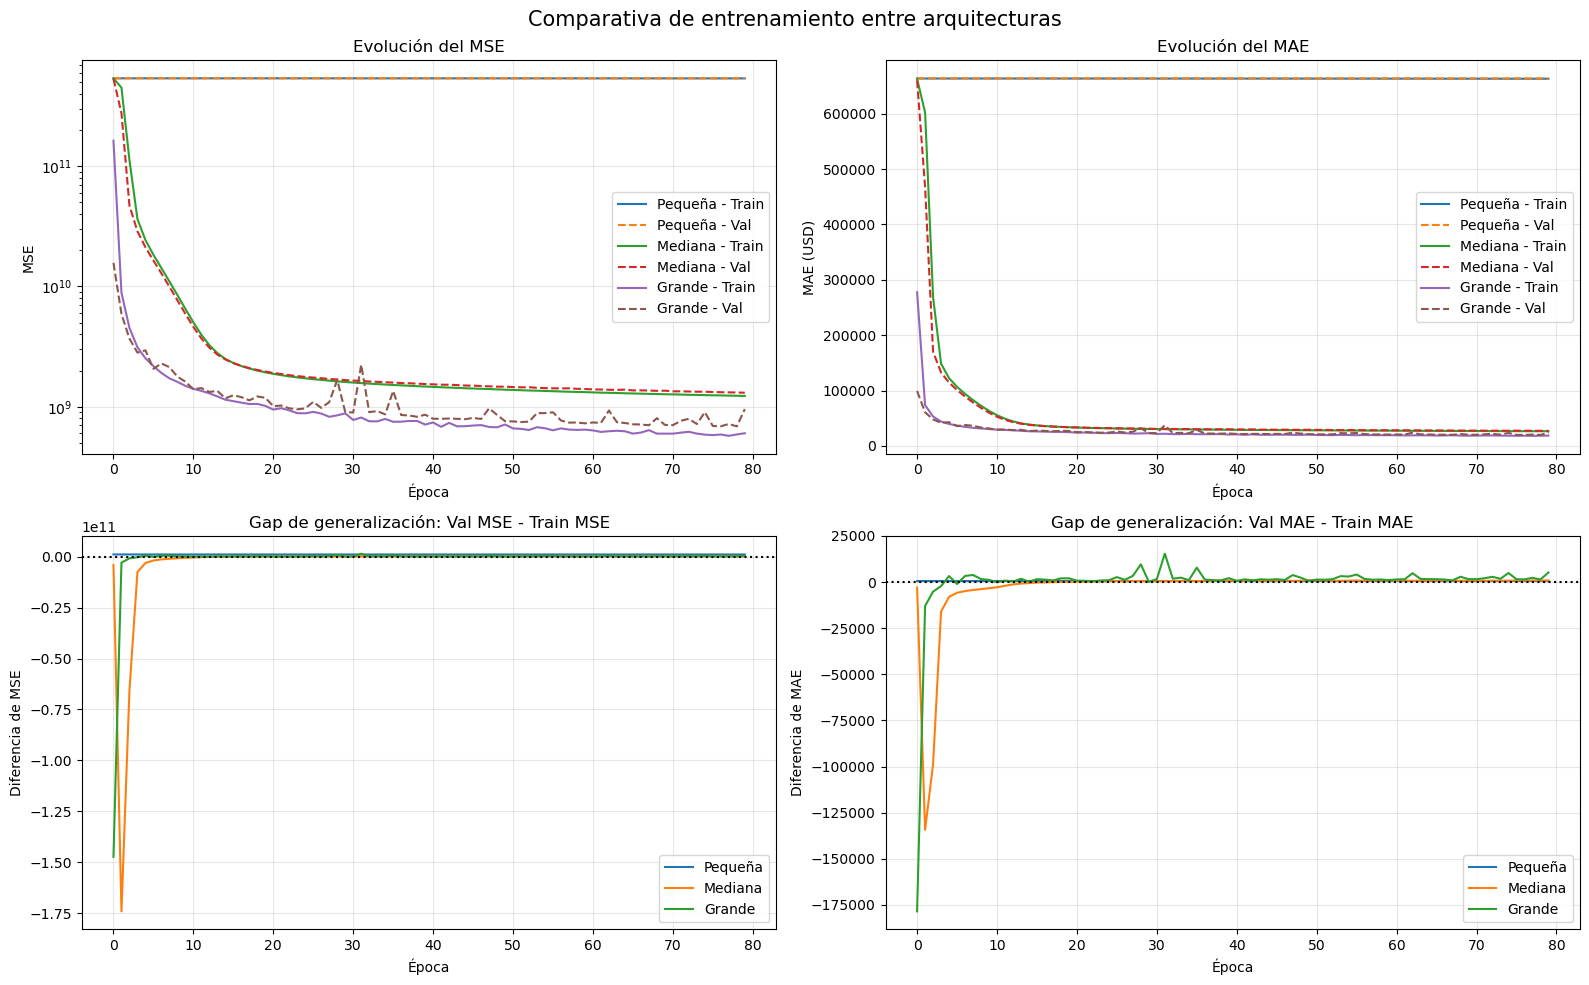

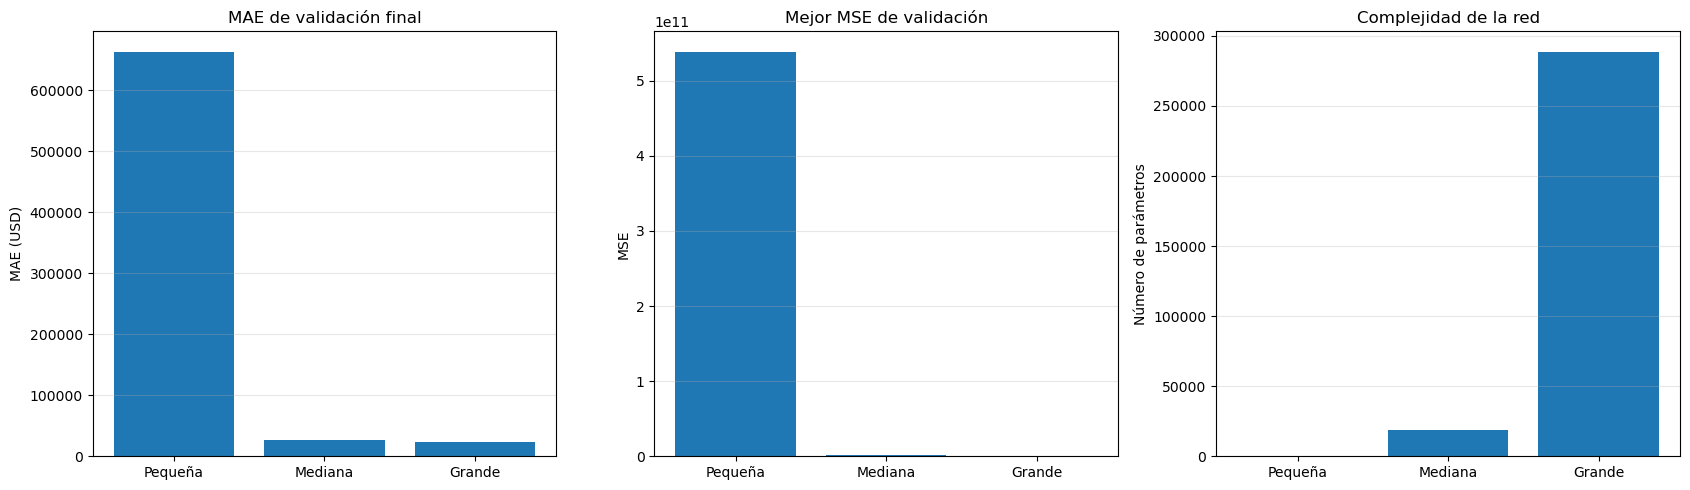

Mejor modelo según MSE de validación: Grande
Mejor modelo según MAE de validación: Grande


In [11]:
# Comparativa completa de los modelos almacenados en histories

comparison_rows = []

for model_name, history in histories.items():
    cfg_model = configs[model_name]

    loss = np.asarray(history["loss"], dtype=float)
    val_loss = np.asarray(history["val_loss"], dtype=float)
    mae = np.asarray(history["mae"], dtype=float)
    val_mae = np.asarray(history["val_mae"], dtype=float)

    best_epoch = int(np.argmin(val_loss))
    input_dim = X_train_scaled.shape[1]
    neurons = cfg_model["neurons"]
    layers = cfg_model["num_layers"]

    # Parámetros de una red densa:
    # primera capa + capas ocultas restantes + salida
    parameters = (
        (input_dim + 1) * neurons
        + max(layers - 1, 0) * (neurons + 1) * neurons
        + (neurons + 1)
    )

    comparison_rows.append({
        "Modelo": model_name,
        "Capas ocultas": layers,
        "Neuronas/capa": neurons,
        "Activación": cfg_model["activation"],
        "Parámetros": parameters,
        "Mejor época": best_epoch + 1,
        "Train MSE final": loss[-1],
        "Val MSE final": val_loss[-1],
        "Train MAE final": mae[-1],
        "Val MAE final": val_mae[-1],
        "Mejor Val MSE": val_loss[best_epoch],
        "Mejor Val MAE": val_mae[np.argmin(val_mae)],
        "Gap MSE final": val_loss[-1] - loss[-1],
        "Gap MAE final": val_mae[-1] - mae[-1],
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values("Capas ocultas")
display(comparison_df.style.format({
    "Train MSE final": "{:,.2f}",
    "Val MSE final": "{:,.2f}",
    "Train MAE final": "{:,.2f}",
    "Val MAE final": "{:,.2f}",
    "Mejor Val MSE": "{:,.2f}",
    "Mejor Val MAE": "{:,.2f}",
    "Gap MSE final": "{:,.2f}",
    "Gap MAE final": "{:,.2f}",
    "Parámetros": "{:,.0f}",
}))

# ---------------------------------------------------------
# Gráficas principales
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# MSE
for model_name, history in histories.items():
    axes[0, 0].plot(history["loss"], label=f"{model_name} - Train")
    axes[0, 0].plot(history["val_loss"], "--", label=f"{model_name} - Val")

axes[0, 0].set_title("Evolución del MSE")
axes[0, 0].set_xlabel("Época")
axes[0, 0].set_ylabel("MSE")
axes[0, 0].set_yscale("log")
axes[0, 0].grid(alpha=0.3)
axes[0, 0].legend()

# MAE
for model_name, history in histories.items():
    axes[0, 1].plot(history["mae"], label=f"{model_name} - Train")
    axes[0, 1].plot(history["val_mae"], "--", label=f"{model_name} - Val")

axes[0, 1].set_title("Evolución del MAE")
axes[0, 1].set_xlabel("Época")
axes[0, 1].set_ylabel("MAE (USD)")
axes[0, 1].grid(alpha=0.3)
axes[0, 1].legend()

# Gap de generalización: MSE
for model_name, history in histories.items():
    train_loss = np.asarray(history["loss"])
    validation_loss = np.asarray(history["val_loss"])
    axes[1, 0].plot(
        validation_loss - train_loss,
        label=model_name
    )

axes[1, 0].axhline(0, color="black", linestyle=":")
axes[1, 0].set_title("Gap de generalización: Val MSE - Train MSE")
axes[1, 0].set_xlabel("Época")
axes[1, 0].set_ylabel("Diferencia de MSE")
axes[1, 0].grid(alpha=0.3)
axes[1, 0].legend()

# Gap de generalización: MAE
for model_name, history in histories.items():
    train_mae = np.asarray(history["mae"])
    validation_mae = np.asarray(history["val_mae"])
    axes[1, 1].plot(
        validation_mae - train_mae,
        label=model_name
    )

axes[1, 1].axhline(0, color="black", linestyle=":")
axes[1, 1].set_title("Gap de generalización: Val MAE - Train MAE")
axes[1, 1].set_xlabel("Época")
axes[1, 1].set_ylabel("Diferencia de MAE")
axes[1, 1].grid(alpha=0.3)
axes[1, 1].legend()

plt.suptitle("Comparativa de entrenamiento entre arquitecturas", fontsize=15)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Comparación visual de las métricas finales
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

model_names = comparison_df["Modelo"]

axes[0].bar(model_names, comparison_df["Val MAE final"])
axes[0].set_title("MAE de validación final")
axes[0].set_ylabel("MAE (USD)")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(model_names, comparison_df["Mejor Val MSE"])
axes[1].set_title("Mejor MSE de validación")
axes[1].set_ylabel("MSE")
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
axes[1].grid(axis="y", alpha=0.3)

axes[2].bar(model_names, comparison_df["Parámetros"])
axes[2].set_title("Complejidad de la red")
axes[2].set_ylabel("Número de parámetros")
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Resumen textual
# ---------------------------------------------------------
best_mse_model = comparison_df.loc[
    comparison_df["Mejor Val MSE"].idxmin(), "Modelo"
]
best_mae_model = comparison_df.loc[
    comparison_df["Mejor Val MAE"].idxmin(), "Modelo"
]

print(f"Mejor modelo según MSE de validación: {best_mse_model}")
print(f"Mejor modelo según MAE de validación: {best_mae_model}")
